# Beyond Static Models: Evaluating Drift-Aware Retraining for Time-Series Anomaly Detection
# Starling 🌟
***Starling is a time-series anomaly detection research project. Its goal is to investigate how different retraining strategies affect anomaly detection when time-series data changes over time.We use NASA SMAP/MSL telemetry data from [Telemanom](https://github.com/khundman/telemanom).***

## Description
This file has been made to do some researches on data and also get some valuable informations from it. <br>
The Repo explores NASA-SMAP/MSL data for Anomaly Detection.

### Dependencies

In [2]:
import numpy as np
from dotenv import load_dotenv
import os
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
load_dotenv()

True

### Data Exploration -> Load

In [3]:
train_data_dir = os.getenv("train_data_dir")
test_data_dir = os.getenv('test_data_dir')
for file_path in Path(train_data_dir).rglob("*.npy"):
    data = np.load(file_path,mmap_mode="r")
    # print(f"\nFile name: {file_path.name}")
    # print(f'data shape: {data.shape}')
    # print('==============================')
    # print(f'data type: {data.dtype}')
    # print('==============================')
    # print(f'First values: ')
    # print(data[:5])



In [4]:
meta_data = pd.read_csv(os.getenv('meta_data'))
print("Spacecraft counts:")
print(meta_data["spacecraft"].value_counts())

print("\nChannels per spacecraft:")
print(
    meta_data.groupby("spacecraft")["chan_id"]
    .agg(["count", "nunique"])
)

print("\nExample channels:")
display(
    meta_data[["chan_id", "spacecraft", "class", "num_values"]]
    
)



duplicates = meta_data[
    meta_data["chan_id"].duplicated(keep=False)
].sort_values("chan_id")

display(duplicates)

Spacecraft counts:
spacecraft
SMAP    55
MSL     27
Name: count, dtype: int64

Channels per spacecraft:
            count  nunique
spacecraft                
MSL            27       27
SMAP           55       54

Example channels:


,chan_id,spacecraft,class,num_values
0,P-1,SMAP,"[contextual, contextual, contextual]",8505
1,S-1,SMAP,[point],7331
2,E-1,SMAP,"[contextual, contextual]",8516
3,E-2,SMAP,[point],8532
4,E-3,SMAP,[point],8307
...,...,...,...,...
77,P-11,MSL,"[point, point]",3535
78,D-15,MSL,[point],2158
79,D-16,MSL,[contextual],2191
80,M-7,MSL,[point],2156


,chan_id,spacecraft,anomaly_sequences,class,num_values
17,P-2,SMAP,"[[5350, 6575]]",[point],8209
51,P-2,SMAP,"[[5300, 6420]]",[point],8209


## 1. Overview
| Item | Result |
|---|---|
| Training channels | 82 |
| Test channels | 82 |
| Data format | NumPy (`.npy`) |
| Target signal | First feature: `data[:, 0]` |
| Anomaly labels | `labeled_anomalies.csv` |

## 2. Validation Results

- All 82 training channels have corresponding test files.
- Arrays contain finite values and matching train/test feature dimensions.
- Anomaly intervals fit within their corresponding test sequences.
- `P-2` has two annotation rows; both are preserved.
- `T-10` has no labels and is excluded from labeled evaluation.

## 3. Important Findings

| Finding | Result |
|---|---|
| Constant training signals | 16 channels |
| Target values outside `[-1, 1]` | 18 train, 21 test channels |
| Severe train/test mismatch | `M-6`: constant training signal, test maximum ≈ 258.11 |

These findings require investigation. **No data has been modified, and no model has been trained yet.**

## 4. Next Steps

1. Visualize `P-2` and its labeled anomaly intervals.
2. Investigate the `M-6` mismatch.
3. Train a baseline anomaly detector.
4. Compare retraining strategies.
5. Introduce MLflow, Airflow, and Docker.

## Visualization

Signal length: 8209
Anomaly intervals:
[[5350, 6575]]
[[5300, 6420]]


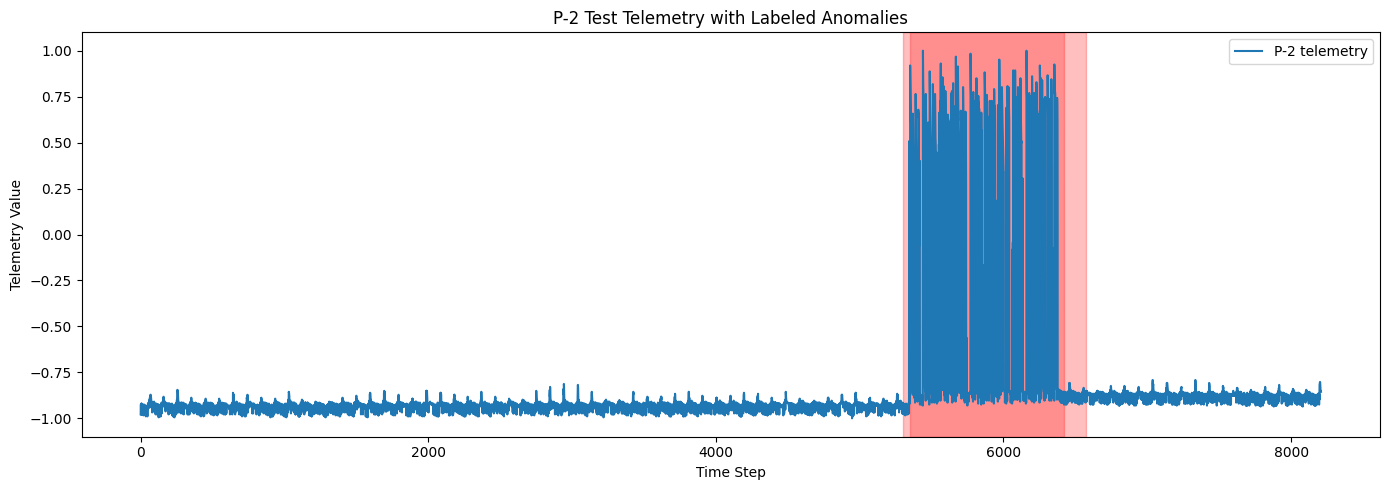

'\nthis plot confirms that the P-2 signal has anomalous signals \n'

In [7]:
# Load P-2 test data
data = np.load(f'{test_data_dir}/P-2.npy')
signal = data[:, 0]

labels = pd.read_csv(os.getenv('meta_data'))
p2_labels = labels[labels["chan_id"] == "P-2"]

print("Signal length:", len(signal))
print("Anomaly intervals:")
print(p2_labels["anomaly_sequences"].to_string(index=False))
plt.figure(figsize=(14, 5))

plt.plot(signal, label="P-2 telemetry")

# Highlight labeled anomaly intervals
for _, row in p2_labels.iterrows():
    intervals = row["anomaly_sequences"]

    # Convert the annotation string into Python lists
    if isinstance(intervals, str):
        intervals = eval(intervals)

    for start, end in intervals:
        plt.axvspan(start, end, alpha=0.25, color="red")

plt.title("P-2 Test Telemetry with Labeled Anomalies")
plt.xlabel("Time Step")
plt.ylabel("Telemetry Value")
plt.legend()
plt.tight_layout()
plt.show()
"""
this plot confirms that the P-2 signal has anomalous signals 
"""

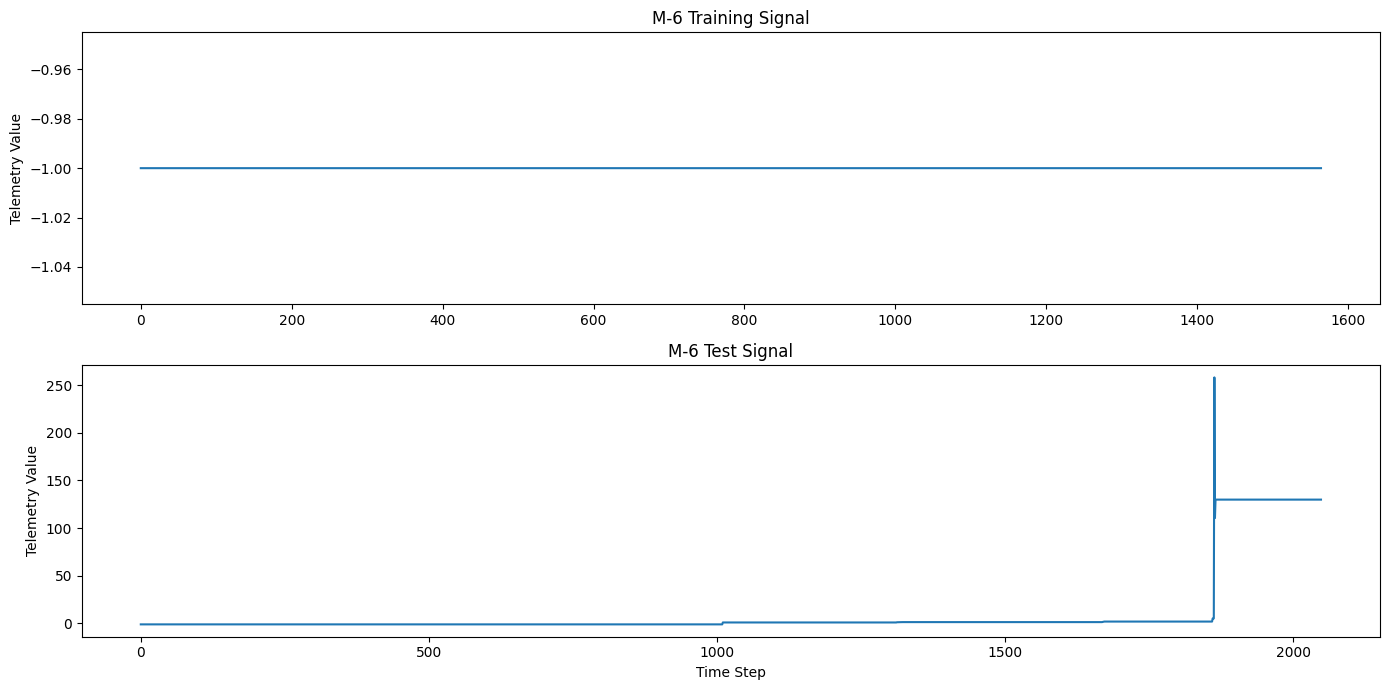

In [ ]:
train = np.load("data/train/M-6.npy")[:, 0]
test = np.load("data/test/M-6.npy")[:, 0]

fig, axes = plt.subplots(2, 1, figsize=(14, 7))

axes[0].plot(train)
axes[0].set_title("M-6 Training Signal")
axes[0].set_ylabel("Telemetry Value")

axes[1].plot(test)
axes[1].set_title("M-6 Test Signal")
axes[1].set_xlabel("Time Step")
axes[1].set_ylabel("Telemetry Value")

plt.tight_layout()
plt.show()

"""
M-6 plot shows that there are differences between train and test signals which is related to data issue or preprocessing
"""